# Model Training and Evaluation

This notebook trains and evaluates three machine-learning
models using the preprocessed GSE38642 dataset.

## Models

1. Logistic Regression
2. Random Forest
3. XGBoost

## Workflow

1. Import libraries
2. Load training and testing datasets
3. Configure cross-validation
4. Tune Logistic Regression
5. Define machine-learning models
6. Perform cross-validation
7. Compare model performance
8. Train the best model
9. Evaluate the model using testing data
10. Save the best model and evaluation results

## 1. Import Libraries

Import the libraries required for model training,
cross-validation, visualization, and evaluation.

The model definitions and evaluation functions are
imported from the `src` directory.

In [12]:
import sys
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import cross_validate

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report
)

# Locate the project directory.
PROJECT_ROOT = Path.cwd()

while (
    not (PROJECT_ROOT / "src").exists()
    and PROJECT_ROOT != PROJECT_ROOT.parent
):
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError(
        "Could not locate the project's src directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# Import project configuration.
from src.config import (
    PROCESSED_DATA_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    TARGET_COLUMN,
    RANDOM_STATE,
    N_SPLITS
)

# Import preprocessing functions.
from src.preprocessing import load_saved_split

# Import model functions.
from src.models import (
    build_logistic_model,
    build_random_forest_model,
    build_xgboost_model
)

# Import evaluation functions.
from src.evaluation import (
    get_scoring_metrics,
    create_stratified_cv,
    evaluate_model
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Training and Testing Data

Load the datasets generated by the preprocessing notebook.

The training dataset is used for model training and
cross-validation.

The testing dataset is kept separate and will only be
used for final model evaluation.

In [13]:
TRAIN_PATH = PROCESSED_DATA_DIR / "train.csv"

TEST_PATH = PROCESSED_DATA_DIR / "test.csv"


if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    raise FileNotFoundError(
        "Training or testing data not found. "
        "Run 02_data_preprocessing.ipynb first."
    )


X_train, y_train = load_saved_split(
    TRAIN_PATH
)

X_test, y_test = load_saved_split(
    TEST_PATH
)


# Ensure the training and testing features match.
if list(X_train.columns) != list(X_test.columns):
    raise ValueError(
        "Training and testing feature columns do not match."
    )


print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting Target Distribution:")
display(y_test.value_counts().sort_index())

Training Features: (50, 18656)
Testing Features: (13, 18656)

Training Target Distribution:


Diabetes_Status
0    43
1     7
Name: count, dtype: int64


Testing Target Distribution:


Diabetes_Status
0    11
1     2
Name: count, dtype: int64

## 3. Cross-Validation Setup

Use Stratified K-Fold cross-validation to evaluate the
models using the training dataset.

Stratification maintains the class distribution in
each fold.

The original project uses five folds. If the minority
class has fewer than five training samples, the number
of folds will be reduced automatically.

In [14]:
cv = create_stratified_cv(
    y_train,
    n_splits=N_SPLITS,
    random_state=RANDOM_STATE
)

scoring = get_scoring_metrics()


print("Cross-validation setup:")
print(cv)

print("\nNumber of folds:", cv.get_n_splits())

print("\nEvaluation Metrics:")
print(list(scoring.keys()))

Cross-validation setup:
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

Number of folds: 5

Evaluation Metrics:
['balanced_accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']


## 4. Logistic Regression Hyperparameter Tuning

Test different values of the regularization parameter C.

The tested values are:

- 0.001
- 0.01
- 0.1
- 1
- 10
- 100

Each configuration is evaluated using stratified
cross-validation.

The best C value is selected based on the mean
PR-AUC score.

In [15]:
C_values = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100
]

logistic_tuning_results = []


for C in C_values:

    print(f"\nTesting Logistic Regression with C = {C}")

    logistic_model = build_logistic_model(
        n_features=X_train.shape[1],
        C=C
    )

    scores = cross_validate(
        logistic_model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    result = {
        "C": C
    }

    for metric in scoring:

        values = scores[f"test_{metric}"]

        result[f"{metric}_mean"] = values.mean()

        result[f"{metric}_std"] = values.std()

        print(
            f"{metric}: "
            f"{values.mean():.4f} "
            f"+/- {values.std():.4f}"
        )

    logistic_tuning_results.append(result)


logistic_tuning_df = pd.DataFrame(
    logistic_tuning_results
)

display(logistic_tuning_df)


Testing Logistic Regression with C = 0.001
balanced_accuracy: 0.5931 +/- 0.1657
precision: 0.2500 +/- 0.3873
recall: 0.3000 +/- 0.4000
f1: 0.2133 +/- 0.2746
roc_auc: 0.8069 +/- 0.2034
pr_auc: 0.6000 +/- 0.3432

Testing Logistic Regression with C = 0.01
balanced_accuracy: 0.5931 +/- 0.1657
precision: 0.2500 +/- 0.3873
recall: 0.3000 +/- 0.4000
f1: 0.2133 +/- 0.2746
roc_auc: 0.8069 +/- 0.2034
pr_auc: 0.6000 +/- 0.3432

Testing Logistic Regression with C = 0.1
balanced_accuracy: 0.6042 +/- 0.1825
precision: 0.2667 +/- 0.3887
recall: 0.3000 +/- 0.4000
f1: 0.2333 +/- 0.2906
roc_auc: 0.8292 +/- 0.2050
pr_auc: 0.6333 +/- 0.3232

Testing Logistic Regression with C = 1
balanced_accuracy: 0.6278 +/- 0.1905
precision: 0.3000 +/- 0.4000
recall: 0.3000 +/- 0.4000
f1: 0.2667 +/- 0.3266
roc_auc: 0.8069 +/- 0.2034
pr_auc: 0.6000 +/- 0.3432

Testing Logistic Regression with C = 10
balanced_accuracy: 0.6278 +/- 0.1905
precision: 0.3000 +/- 0.4000
recall: 0.3000 +/- 0.4000
f1: 0.2667 +/- 0.3266
roc_auc:

,C,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,0.001,0.593056,0.165715,0.250000,0.387298,0.3,0.4,0.213333,0.274550,0.806944,0.203386,0.600000,0.343188
1,0.010,0.593056,0.165715,0.250000,0.387298,0.3,0.4,0.213333,0.274550,0.806944,0.203386,0.600000,0.343188
2,0.100,0.604167,0.182468,0.266667,0.388730,0.3,0.4,0.233333,0.290593,0.829167,0.205048,0.633333,0.323179
3,1.000,0.627778,0.190516,0.300000,0.400000,0.3,0.4,0.266667,0.326599,0.806944,0.203386,0.600000,0.343188
4,10.000,0.627778,0.190516,0.300000,0.400000,0.3,0.4,0.266667,0.326599,0.784722,0.211276,0.583333,0.357460
5,100.000,0.627778,0.190516,0.300000,0.400000,0.3,0.4,0.266667,0.326599,0.784722,0.211276,0.583333,0.357460


## 5. Select Best Logistic Regression Parameter

Select the C value that produces the highest mean
PR-AUC score during cross-validation.

In [16]:
best_logistic_row = logistic_tuning_df.loc[
    logistic_tuning_df["pr_auc_mean"].idxmax()
]

best_C = float(
    best_logistic_row["C"]
)

print("Best Logistic Regression C:", best_C)

print(
    "Best Mean PR-AUC:",
    round(best_logistic_row["pr_auc_mean"], 4)
)

Best Logistic Regression C: 0.1
Best Mean PR-AUC: 0.6333


## 6. Define Machine Learning Models

Create the three machine-learning pipelines.

Each pipeline includes:

- Median imputation for missing numerical values
- Feature selection using SelectKBest

Logistic Regression also uses StandardScaler.

The model configurations are based on the original
project's hyperparameters.

In [17]:
# Logistic Regression
logistic_model = build_logistic_model(
    n_features=X_train.shape[1],
    C=best_C
)


# Random Forest
rf_model = build_random_forest_model(
    n_features=X_train.shape[1]
)


# XGBoost
xgb_model = build_xgboost_model(
    n_features=X_train.shape[1]
)


# Store the models in a dictionary.
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}


print("Models defined successfully.")

for model_name in models:
    print("-", model_name)

Models defined successfully.
- Logistic Regression
- Random Forest
- XGBoost


## 7. Model Cross-Validation

Evaluate each model using the training dataset.

The evaluation metrics include:

- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- PR-AUC

The mean and standard deviation of each metric are
calculated across the cross-validation folds.

In [18]:
cv_results = {}

comparison_rows = []


for name, model in models.items():

    print(f"\nTraining {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results[name] = scores

    result = {
        "Model": name
    }

    print(f"\n{name} Results:")

    for metric in scoring:

        values = scores[f"test_{metric}"]

        mean_score = values.mean()

        std_score = values.std()

        result[f"{metric}_mean"] = mean_score

        result[f"{metric}_std"] = std_score

        print(
            f"{metric}: "
            f"{mean_score:.4f} "
            f"+/- {std_score:.4f}"
        )

    comparison_rows.append(result)


comparison_df = pd.DataFrame(
    comparison_rows
)

display(comparison_df)


Training Logistic Regression...

Logistic Regression Results:
balanced_accuracy: 0.6042 +/- 0.1825
precision: 0.2667 +/- 0.3887
recall: 0.3000 +/- 0.4000
f1: 0.2333 +/- 0.2906
roc_auc: 0.8292 +/- 0.2050
pr_auc: 0.6333 +/- 0.3232

Training Random Forest...

Random Forest Results:
balanced_accuracy: 0.5667 +/- 0.1625
precision: 0.0667 +/- 0.1333
recall: 0.2000 +/- 0.4000
f1: 0.1000 +/- 0.2000
roc_auc: 0.8417 +/- 0.2056
pr_auc: 0.6500 +/- 0.3180

Training XGBoost...

XGBoost Results:
balanced_accuracy: 0.5667 +/- 0.1937
precision: 0.1000 +/- 0.2000
recall: 0.2000 +/- 0.4000
f1: 0.1333 +/- 0.2667
roc_auc: 0.5500 +/- 0.4053
pr_auc: 0.3756 +/- 0.2226


,Model,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,Logistic Regression,0.604167,0.182468,0.266667,0.388730,0.3,0.4,0.233333,0.290593,0.829167,0.205048,0.633333,0.323179
1,Random Forest,0.566667,0.162542,0.066667,0.133333,0.2,0.4,0.100000,0.200000,0.841667,0.205556,0.650000,0.317980
2,XGBoost,0.566667,0.193729,0.100000,0.200000,0.2,0.4,0.133333,0.266667,0.550000,0.405270,0.375556,0.222572


## 8. Model Comparison

Compare the cross-validation results of the three models.

PR-AUC is used as the primary metric for selecting
the best model because it is useful when evaluating
classification performance with imbalanced classes.

The model with the highest mean PR-AUC is selected.

In [19]:
comparison_df = comparison_df.sort_values(
    by="pr_auc_mean",
    ascending=False
).reset_index(drop=True)


print("Model Ranking:")

display(comparison_df)


best_model_name = comparison_df.loc[
    0,
    "Model"
]

print("\nBest Model:", best_model_name)

print(
    "Best Cross-Validation PR-AUC:",
    round(
        comparison_df.loc[0, "pr_auc_mean"],
        4
    )
)

Model Ranking:


,Model,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,Random Forest,0.566667,0.162542,0.066667,0.133333,0.2,0.4,0.100000,0.200000,0.841667,0.205556,0.650000,0.317980
1,Logistic Regression,0.604167,0.182468,0.266667,0.388730,0.3,0.4,0.233333,0.290593,0.829167,0.205048,0.633333,0.323179
2,XGBoost,0.566667,0.193729,0.100000,0.200000,0.2,0.4,0.133333,0.266667,0.550000,0.405270,0.375556,0.222572



Best Model: Random Forest
Best Cross-Validation PR-AUC: 0.65


## 9. Save Cross-Validation Results

Save the model comparison and Logistic Regression
hyperparameter tuning results.

These files can be used later for project reporting.

In [20]:
METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


comparison_path = (
    METRICS_DIR / "model_comparison.csv"
)

tuning_path = (
    METRICS_DIR / "logistic_tuning.csv"
)


comparison_df.to_csv(
    comparison_path,
    index=False
)

logistic_tuning_df.to_csv(
    tuning_path,
    index=False
)


print("Model comparison saved to:")
print(comparison_path)

print("\nLogistic tuning results saved to:")
print(tuning_path)

Model comparison saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\metrics\model_comparison.csv

Logistic tuning results saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\metrics\logistic_tuning.csv


## 10. Train the Best Model

Retrieve the best-performing model based on the
cross-validation comparison.

Train it using the complete training dataset.

The testing dataset remains separate.

In [21]:
best_model = models[best_model_name]

best_model.fit(
    X_train,
    y_train
)

print("Best model trained successfully.")

print("Model:", best_model_name)

Best model trained successfully.
Model: Random Forest


## 11. Final Model Evaluation

Evaluate the trained model using the previously
separated testing dataset.

The testing dataset has not been used during model
training or cross-validation.

Evaluation metrics include:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- PR-AUC

In [22]:
test_metrics, y_pred, y_probability = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_metrics_df = pd.DataFrame(
    test_metrics.items(),
    columns=["Metric", "Score"]
)

print("Final Testing Results:")

display(
    test_metrics_df.round(4)
)

Final Testing Results:


,Metric,Score
0,accuracy,0.9231
1,balanced_accuracy,0.7500
2,precision,1.0000
3,recall,0.5000
4,f1,0.6667
5,roc_auc,0.7273
6,pr_auc,0.6250


## 12. Classification Report

Display the precision, recall, and F1 score for
each diabetes class.

Class 0 represents the negative class.

Class 1 represents the positive class.

In [23]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Negative Class",
            "Positive Class"
        ],
        zero_division=0
    )
)

                precision    recall  f1-score   support

Negative Class       0.92      1.00      0.96        11
Positive Class       1.00      0.50      0.67         2

      accuracy                           0.92        13
     macro avg       0.96      0.75      0.81        13
  weighted avg       0.93      0.92      0.91        13



## 13. Confusion Matrix

Visualize the predictions made by the best-performing
model.

The confusion matrix contains:

- True Negatives
- False Positives
- False Negatives
- True Positives

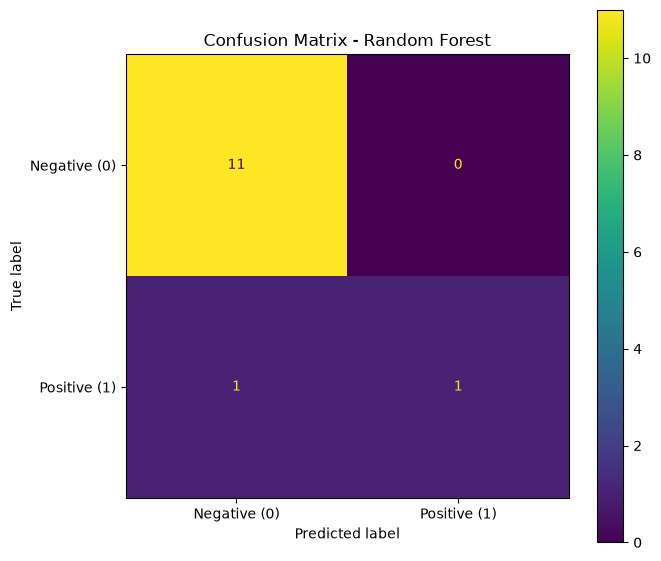

Confusion matrix saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\figures\confusion_matrix.png


In [24]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=[
        "Negative (0)",
        "Positive (1)"
    ],
    ax=ax
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.tight_layout()

confusion_matrix_path = (
    FIGURES_DIR / "confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved to:")
print(confusion_matrix_path)

## 14. Save Final Evaluation Metrics

Save the final testing metrics to a CSV file.

In [25]:
test_metrics_path = (
    METRICS_DIR / "final_test_metrics.csv"
)

test_metrics_df.to_csv(
    test_metrics_path,
    index=False
)

print("Final testing metrics saved to:")
print(test_metrics_path)

Final testing metrics saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\metrics\final_test_metrics.csv


## 15. Save Best Model

Save the trained model using joblib.

The model can then be loaded by the SHAP analysis
notebook without having to train it again.

Also save basic model information for future reference.

In [26]:
MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


MODEL_PATH = (
    MODELS_DIR / "best_model.joblib"
)

METADATA_PATH = (
    MODELS_DIR / "model_metadata.json"
)


# Save trained model.
joblib.dump(
    best_model,
    MODEL_PATH
)


# Save model information.
model_metadata = {
    "best_model_name": best_model_name,
    "target_column": TARGET_COLUMN,
    "best_logistic_C": best_C,
    "positive_class": 1,
    "selection_metric": "pr_auc",
    "feature_count": int(X_train.shape[1])
}


with open(
    METADATA_PATH,
    "w"
) as file:

    json.dump(
        model_metadata,
        file,
        indent=4
    )


print("Best model saved to:")
print(MODEL_PATH)

print("\nModel metadata saved to:")
print(METADATA_PATH)

Best model saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\models\best_model.joblib

Model metadata saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\models\model_metadata.json


## 16. Training Summary

The model training and evaluation process is complete.

The best-performing model was selected using
cross-validation PR-AUC.

The selected model was trained on the complete
training dataset and evaluated using the separate
testing dataset.

The trained model and evaluation results have
been saved in the results directory.

The next notebook will use SHAP to interpret
the selected model's predictions.